# HFR simulation – publication plot
Simulate HFR for charge and discharge, compare against experiment.  
Plot style: single black model curve, filled circles (charge) and open circles (discharge).  
**Workflow:** edit the *Parameters* cell -> run all -> read the plot.

In [ ]:
import sys, os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).resolve()
while not (PROJECT_ROOT / 'setup.py').exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError('Cannot find project root')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from pathlib import Path
from solve_dae.integrate import solve_dae
import json

ROOT = Path("../..").resolve()
sys.path.insert(0, str(ROOT / "scripts" / "Experimental"))

from simulate_HFR import build_cell, build_atol, soc_cutoff_event  # noqa: E402
from rfbmodel1D.parameters.params import membraneparams, cathodeparams, anodeparams  # noqa: E402

## -- Parameters --

In [12]:
# -- test selection -------------------------------------------------------------
TEST_NO = 25

# -- solver settings ------------------------------------------------------------
TF     = 1800
RTOL   = 1e-5
STRIDE = 1

In [13]:
# -- Load fitted parameters -----------------------------------------------------
fit_dir  = ROOT / "results" / "test fitting" / f"test {TEST_NO}"
fit_path = sorted(fit_dir.glob(f"fit_v2_test{TEST_NO}_*.json"))[-1]
with open(fit_path, "r") as f:
    fit = json.load(f)
# -- apply parameters of HFR fitting -----------------------------------------------
membraneparams.k_sorp_vw   = fit["params"]["k_vw_sorp"]
membraneparams.k_desorp_vw = fit["params"]["S_desorp"] * fit["params"]["k_vw_sorp"]
membraneparams.k_sorp_lw   = fit["params"]["k_lw_sorp"]
membraneparams.k_desorp_lw = fit["params"]["S_desorp"] * fit["params"]["k_lw_sorp"]
membraneparams.k_ca_lw     = fit["params"]["k_ca"]
membraneparams.sf_D        = fit["settings"]["sf_D"]
R_EXTRA                     = fit["params"]["R_extra (Ω·cm²)"] / 1e4    # Ω·m²
# -- apply parameters of E fitting -----------------------------------------------
if sorted(fit_dir.glob(f"fit_e_cell_test{TEST_NO}_*.json"))[-1].name is not None:
    print("Applying E fitting parameters...")
    E_CELL_FIT = sorted(fit_dir.glob(f"fit_e_cell_test{TEST_NO}_*.json"))[-1].name
    with open(fit_dir / E_CELL_FIT, "r") as f:
        fit_e_cell = json.load(f)
    cathodeparams.reaction_rate_constant = fit_e_cell["params"]["k_ca"]
    anodeparams.j_0                      = fit_e_cell["params"]["j0_an"]
# -- load experimental data -----------------------------------------------------
csv  = ROOT / "data" / "experimental" / "HFR.csv"
data = pd.read_csv(csv)
data = data[data["test_no"] == TEST_NO]

soc = data["SOC"].iloc[0]
T   = data["T(°C)"].iloc[0]
Q_v = data["Q_v (ml/min)"].iloc[0]

j_charge    = data[data["mode"] == "charge"]["j_appl (A/m2)"].values[::STRIDE]
j_discharge = data[data["mode"] == "discharge"]["j_appl (A/m2)"].values[::STRIDE]
HFR_exp_ch  = data[data["mode"] == "charge"]["value (ohm cm2)"].values[::STRIDE]
HFR_exp_dis = data[data["mode"] == "discharge"]["value (ohm cm2)"].values[::STRIDE]

print(f"Test {TEST_NO}: SOC={soc}, T={T}°C, Q_v={Q_v} ml/min")
print(f"Charge: {len(j_charge)} pts   Discharge: {len(j_discharge)} pts")

Applying E fitting parameters...
Test 25: SOC=0.9, T=32°C, Q_v=45 ml/min
Charge: 12 pts   Discharge: 14 pts


## -- Run simulations --

In [14]:
def run_sim(j_appl: float):
    """Return (HFR [Ω·cm²], lam_profile, x_mem)."""
    cell, y0, yp0 = build_cell(soc, j_appl, T, Q_v)
    atol = build_atol(cell)
    jac_sparsity = cell.compute_jac_sparsity(y0, yp0)
    t0 = time.time()
    sol = solve_dae(
        cell.dae_residual_full_cell,
        (0.0, TF), y0, yp0,
        method="BDF", atol=atol, rtol=RTOL,
        events=soc_cutoff_event, jac_sparsity=jac_sparsity,
    )
    cell.dae_residual_full_cell(sol.t[-1], sol.y[:, -1], sol.yp[:, -1])
    if sol.t[-1] < 0.99 * TF:
        print(f"  Warning: Simulation terminated early at t={sol.t[-1]:.1f}s (event triggered).")

    state       = cell.split_state(sol.y[:, -1])
    lam_profile = state["membrane"][:, 0]
    x_mem       = cell.mesh.membrane_mesh.x_grid

    kappa_io_ca = cell.cathode.kappa_io
    sigma_ca    = np.ones_like(kappa_io_ca) * cell.cathode.eff_conductivity
    dx_ca       = cell.mesh.cathode_mesh.dx * cell.cathode.thickness
    R_cathode   = sum(dx_ca / (sigma_ca + kappa_io_ca))

    kappa_io_m = cell.membrane.kappa_io
    dx_m       = cell.mesh.membrane_mesh.dx * cell.membrane.thickness
    R_membrane = sum(dx_m / kappa_io_m)

    R_ACL  = cell.anode.thickness  / cell.anode.eff_conductivity
    R_AGDL = cell.agdl.thickness   / cell.agdl.eff_conductivity
    R_BP   = cell.thickness_BP / cell.sigma_BP
    R_CC   = cell.thickness_CC / cell.sigma_CC
    HFR    = (R_cathode + R_membrane + R_ACL + R_AGDL + R_BP + R_CC + R_EXTRA) * 1e4

    print(f"  j={j_appl:+8.0f} A/m²  HFR={HFR:.4f} Ω·cm²  ({time.time()-t0:.1f}s)")
    return HFR, lam_profile, x_mem


def interior_points(arr, n=1):
    """Return n equally-spaced interior points between each consecutive pair."""
    pts = []
    for a, b in zip(arr[:-1], arr[1:]):
        pts.extend(np.linspace(a, b, n + 2)[1:-1])
    return np.array(pts)


# -- Charge --------------------------------------------------------------------
print("=== Charge ===")
_res_ch    = [run_sim(float(j))  for j in j_charge]
HFR_sim_ch = [r[0] for r in _res_ch]
lam_ch     = [r[1] for r in _res_ch]
x_mem      = _res_ch[0][2]

j_ch_fill  = interior_points(j_charge, n=1)
print("=== Charge fill points ===")
HFR_sim_ch_fill = [run_sim(float(j))[0] for j in j_ch_fill]

j_model_ch   = np.concatenate([j_charge,    j_ch_fill])
HFR_model_ch = np.concatenate([HFR_sim_ch, HFR_sim_ch_fill])
sort_idx     = np.argsort(j_model_ch)
j_model_ch   = j_model_ch[sort_idx]
HFR_model_ch = HFR_model_ch[sort_idx]

# -- Discharge -----------------------------------------------------------------
print("=== Discharge ===")
_res_dis    = [run_sim(-float(j)) for j in j_discharge]
HFR_sim_dis = [r[0] for r in _res_dis]
lam_dis     = [r[1] for r in _res_dis]

j_dis_fill  = interior_points(j_discharge, n=3)
print("=== Discharge fill points ===")
HFR_sim_dis_fill = [run_sim(-float(j))[0] for j in j_dis_fill]

j_model_dis   = np.concatenate([j_discharge,    j_dis_fill])
HFR_model_dis = np.concatenate([HFR_sim_dis, HFR_sim_dis_fill])
sort_idx      = np.argsort(j_model_dis)
j_model_dis   = j_model_dis[sort_idx]
HFR_model_dis = HFR_model_dis[sort_idx]

# -- MSE (original points only) -----------------------------------------------
HFR_exp_all = np.concatenate([HFR_exp_ch, HFR_exp_dis])
HFR_sim_all = np.array(HFR_sim_ch + HFR_sim_dis)
mse = float(np.mean((HFR_sim_all - HFR_exp_all) ** 2))
print(f"\nMSE = {mse:.6f}  RMSE = {mse**0.5:.4f} Ω·cm²")

=== Charge ===
  j=     +24 A/m²  HFR=0.4946 Ω·cm²  (1.8s)
  j=     +95 A/m²  HFR=0.4928 Ω·cm²  (1.2s)
  j=    +202 A/m²  HFR=0.4903 Ω·cm²  (0.8s)
  j=    +310 A/m²  HFR=0.4880 Ω·cm²  (1.1s)
  j=    +440 A/m²  HFR=0.4847 Ω·cm²  (1.4s)
  j=    +613 A/m²  HFR=0.4803 Ω·cm²  (2.1s)
  j=    +810 A/m²  HFR=0.4783 Ω·cm²  (10.1s)
  j=   +1012 A/m²  HFR=0.4847 Ω·cm²  (8.5s)
  j=   +1244 A/m²  HFR=0.4918 Ω·cm²  (8.1s)
  j=   +1500 A/m²  HFR=0.5005 Ω·cm²  (10.1s)
  j=   +1744 A/m²  HFR=0.5099 Ω·cm²  (11.8s)
  j=   +1994 A/m²  HFR=0.5208 Ω·cm²  (13.6s)
=== Charge fill points ===
  j=     +60 A/m²  HFR=0.4937 Ω·cm²  (1.1s)
  j=    +149 A/m²  HFR=0.4915 Ω·cm²  (1.1s)
  j=    +256 A/m²  HFR=0.4891 Ω·cm²  (0.8s)
  j=    +375 A/m²  HFR=0.4866 Ω·cm²  (1.5s)
  j=    +527 A/m²  HFR=0.4836 Ω·cm²  (1.2s)
  j=    +711 A/m²  HFR=0.4763 Ω·cm²  (7.4s)
  j=    +911 A/m²  HFR=0.4819 Ω·cm²  (9.1s)
  j=   +1128 A/m²  HFR=0.4881 Ω·cm²  (8.6s)
  j=   +1372 A/m²  HFR=0.4960 Ω·cm²  (9.1s)
  j=   +1622 A/m²  HFR=0.5051 

In [ ]:
# -- MSE (original points only) -----------------------------------------------
HFR_exp_all = np.concatenate([HFR_exp_ch, HFR_exp_dis])
HFR_sim_all = np.array(HFR_sim_ch + HFR_sim_dis)
mse = float(np.mean((HFR_sim_all - HFR_exp_all) ** 2))
print(f"\nMSE = {mse:.6f}  RMSE = {mse**0.5:.4f} Ω·cm²")

# -- Save results for combined plotting --------------------------------------
save_path = ROOT / f"results/test{TEST_NO}_results.npz"
save_path.parent.mkdir(parents=True, exist_ok=True)

np.savez(
    save_path,
    # HFR curves
    j_discharge=j_discharge,
    HFR_exp_dis=HFR_exp_dis,
    j_charge=j_charge,
    HFR_exp_ch=HFR_exp_ch,
    j_model_ch=j_model_ch,
    HFR_model_ch=HFR_model_ch,
    j_model_dis=j_model_dis,
    HFR_model_dis=HFR_model_dis,
    # lambda profiles — only at the original j_charge/j_discharge points
    x_mem=x_mem,
    lam_ch=np.array(lam_ch),    # shape (n_charge_points, n_x)
    lam_dis=np.array(lam_dis),  # shape (n_discharge_points, n_x)
    j_charge_lam=j_charge,      # j values corresponding to lam_ch rows
    j_discharge_lam=j_discharge,  # j values corresponding to lam_dis rows
    # fit quality
    mse=mse,
)
print(f"Saved results to {save_path}")

## -- Results --

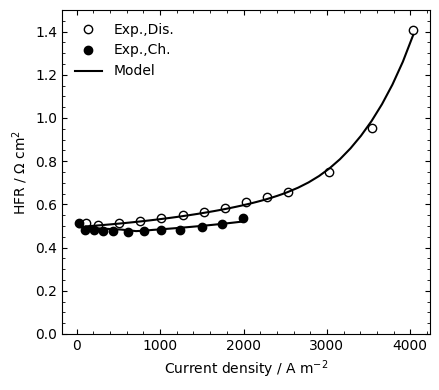

In [16]:
fig, ax = plt.subplots(figsize=(4.5, 4))

# Experimental: filled circles (charge), open circles (discharge)
ax.plot(j_discharge, HFR_exp_dis, 'o', ms=6, mfc='none', mec='k', mew=1.0,
        label='Exp.,Dis.')
ax.plot(j_charge,    HFR_exp_ch,  'o', ms=6, mfc='k',    mec='k', mew=1.0,
        label='Exp.,Ch.')

# Model: denser black line (original + midpoints, sorted)
ax.plot(j_model_ch,  HFR_model_ch,  '-', color='k', lw=1.5, label='Model')
ax.plot(j_model_dis, HFR_model_dis, '-', color='k', lw=1.5)

ax.set_xlabel('Current density / A m$^{-2}$')
ax.set_ylabel('HFR / $\\Omega$ cm$^2$')
ax.legend(frameon=False)
ax.set_ylim(0, 1.5)
ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.tick_params(which='both', direction='in', top=True, right=True)

plt.tight_layout()
out_path = ROOT / f"figures/HFR_test{TEST_NO}.pdf"
out_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_path, bbox_inches='tight')
plt.show()